
# DCMC-Fusion: Data-centric Analysis

## Objective

Analyze two effects associated with the datasets used to train the fusion classifiers:

- **Composition effect:** Differences in classification performance among architectural combinations for a fixed $K$.
- **Size effect:** Changes in average classification performance as the number of architectures ($K$) increases.

## Input files

This notebook requires five CSV files generated by the corresponding `DCMC_Fusion_Ki` experimental notebooks:

| Input file | K | Datasets | Experimental configurations |
|---|---|---|---|
| `global_metrics_k1.csv` | 1 | 5 | 20 |
| `global_metrics_k2.csv` | 2 | 10 | 40 |
| `global_metrics_k3.csv` | 3 | 10 | 40 |
| `global_metrics_k4.csv` | 4 | 5 | 20 |
| `global_metrics_k5.csv` | 5 | 1 | 4 |
| **Total** | | **31** | **124** |

Each CSV file contains the global performance metrics obtained by four fusion classifiers: Logistic Regression (LR), Random Forest (RF), Support Vector Machine (SVM), and XGBoost.

**File location:** All five CSV files must be placed in `/content/` when running the notebook in Google Colab.

## Data processing and visualization

The five CSV files are combined into a single dataset containing 124 experimental configurations.

For each architectural combination, the F1-macro scores of the four fusion classifiers are averaged, resulting in 31 values.

The results are presented in a scatter plot:

- **Blue circles:** Each circle represents one architectural combination and summarizes the F1-macro of four experimental configurations.
- **Orange diamonds:** Each diamond represents the average F1-macro across all architectural combinations corresponding to the same $K$.

This representation allows the composition and size effects to be analyzed jointly.

**Important:** This notebook only processes and visualizes previously obtained experimental results. No fusion classifiers or deep-learning models are retrained.


## 1. Libraries and paths
Place the five `global_metrics_k*.csv` files in the same folder as this notebook (or update `DATA_DIR`).

In [1]:
from pathlib import Path

BASE_DIR = Path("/content")

FILES = {
    k: BASE_DIR / f"global_metrics_k{k}.csv"
    for k in range(1, 6)
}

OUTPUT_DIR = BASE_DIR / "data_centric_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_DATASETS = {1: 5, 2: 10, 3: 10, 4: 5, 5: 1}
EXPECTED_CLASSIFIERS = {"Logistic Regression", "Random Forest", "XGBoost", "SVM"}

## 2. Load and validate experimental results

In [2]:

from pathlib import Path
import pandas as pd

# Directorio de trabajo en Google Colab
DATA_DIR = Path("/content")

# Archivos de resultados
files = [
    DATA_DIR / f"global_metrics_k{k}.csv"
    for k in range(1, 6)
]

# Verificar que existan los cinco archivos
missing_files = [str(path) for path in files if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}"
    )

# Cargar y combinar resultados
results = pd.concat(
    [pd.read_csv(path) for path in files],
    ignore_index=True
)

# Validar columnas
required = {"K", "architectures", "classifier", "f1_macro"}
missing = required - set(results.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# Validar número total de evaluaciones
if len(results) != 124:
    raise ValueError(
        f"Expected 124 rows; found {len(results)}"
    )

# Validar clasificadores por dataset
for (k, arch), group in results.groupby(["K", "architectures"]):
    if (
        len(group) != 4
        or set(group["classifier"]) != EXPECTED_CLASSIFIERS
    ):
        raise ValueError(
            f"Unexpected classifiers or duplicates for K={k}, {arch}"
        )

# Validar número de datasets por K
counts = results.groupby("K")["architectures"].nunique().to_dict()

if counts != EXPECTED_DATASETS:
    raise ValueError(
        f"Unexpected number of datasets by K: {counts}"
    )

print(
    f"Validated {len(results)} evaluations "
    f"across {sum(counts.values())} datasets"
)

display(results.head())


Validated 124 evaluations across 31 datasets


,K,architectures,classifier,accuracy,precision_macro,recall_macro,f1_macro
0,1,resnet50,Logistic Regression,0.656836,0.658851,0.656836,0.655745
1,1,resnet50,Random Forest,0.691689,0.710685,0.691689,0.684579
2,1,resnet50,XGBoost,0.693029,0.707031,0.693029,0.687750
3,1,resnet50,SVM,0.684987,0.707556,0.684987,0.676184
4,1,densenet121,Logistic Regression,0.655496,0.655506,0.655496,0.655490


## 3. Mean performance per dataset
The mean is descriptive: $\overline{F1}_{K,j}=\frac{1}{4}\sum_{c=1}^{4}F1_{K,j,c}$.

In [3]:
points = (
    results.groupby(["K", "architectures"], as_index=False)
    .agg(f1_mean=("f1_macro", "mean"),
         f1_std_classifiers=("f1_macro", "std"))
    .sort_values(["K", "f1_mean"], ascending=[True, False])
)
display(points)

,K,architectures,f1_mean,f1_std_classifiers
4,1,vgg16,0.694531,0.001392
0,1,densenet121,0.680228,0.023494
3,1,resnet50,0.676065,0.014398
1,1,inception_v3,0.668086,0.009051
2,1,resnet34,0.628005,0.034868
14,2,resnet50 + vgg16,0.702463,0.005663
9,2,inception_v3 + vgg16,0.697561,0.002938
7,2,densenet121 + vgg16,0.696976,0.013878
10,2,resnet34 + vgg16,0.696232,0.006675
11,2,resnet50 + densenet121,0.694886,0.018722


## 4. Summary by K
Standard deviation here describes variation **between architectural combinations**, not statistical confidence. It is undefined for $K=5$, which has only one combination.

In [4]:
summary = (
    points.groupby("K")
    .agg(datasets=("f1_mean", "size"),
         mean=("f1_mean", "mean"),
         std=("f1_mean", "std"),
         minimum=("f1_mean", "min"),
         maximum=("f1_mean", "max"))
    .reset_index()
)
display(summary.round(5))

,K,datasets,mean,std,minimum,maximum
0,1,5,0.66938,0.02504,0.62801,0.69453
1,2,10,0.69103,0.00806,0.67668,0.70246
2,3,10,0.69604,0.00642,0.68616,0.70471
3,4,5,0.70131,0.00494,0.69251,0.70428
4,5,1,0.70677,NaN,0.70677,0.70677


## 5. Scatter plot — composition and size effects
Each dot is one dataset; diamonds indicate the mean across combinations at the corresponding $K$. No horizontal jitter is applied.

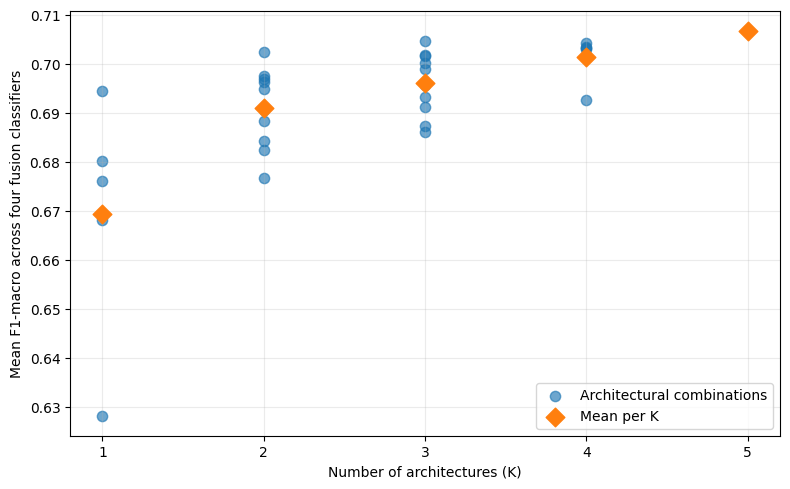

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(points["K"], points["f1_mean"], s=55, alpha=0.65,
           label="Architectural combinations")
ax.scatter(summary["K"], summary["mean"], s=90, marker="D", zorder=4,
           label="Mean per K")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Number of architectures (K)")
ax.set_ylabel("Mean F1-macro across four fusion classifiers")
#ax.set_title("Data-centric analysis: composition and size effects")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "data_centric_scatter.png", dpi=220, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "data_centric_scatter.pdf", bbox_inches="tight")
plt.show()

## 6. Export numerical summaries

In [6]:
points.to_csv(OUTPUT_DIR / "data_centric_points.csv", index=False)
summary.to_csv(OUTPUT_DIR / "data_centric_summary.csv", index=False)
print(f"Figures and CSV summaries saved in: {OUTPUT_DIR.resolve()}")

Figures and CSV summaries saved in: /content/data_centric_results


## Interpretation notes

- **Composition:** inspect the vertical spread of dots at each fixed $K$.
- **Size:** compare the mean diamonds across values of $K$.
- A higher mean across datasets does **not** imply that every individual configuration improves.
- These summaries describe the evaluated configurations; they do not by themselves establish statistical significance or eliminate all selection bias.